<a href="https://colab.research.google.com/github/SKM1919/liftlens/blob/main/notebooks/03_criteo_uplift.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LiftLens: Criteo Uplift (Hard tier)
Goal: scale uplift modelling to a large, imbalanced, real-world advertising experiment.

In [4]:
!mkdir -p data
!wget -q --show-progress -O data/criteo-uplift-v2.1.csv.gz \
  https://huggingface.co/datasets/criteo/criteo-uplift/resolve/main/criteo-research-uplift-v2.1.csv.gz

data/criteo-uplift- 100%[===================>] 297.00M  90.9MB/s    in 3.3s    


In [5]:
!pip install scikit-uplift xgboost -q

import pandas as pd
import numpy as np

SAMPLE_FRAC = 0.10
rng = np.random.default_rng(42)

chunks = []
for chunk in pd.read_csv('data/criteo-uplift-v2.1.csv.gz',
                         chunksize=1_000_000, dtype='float32'):
    chunks.append(chunk.sample(frac=SAMPLE_FRAC, random_state=rng))

df = pd.concat(chunks, ignore_index=True)

# Labels are 0/1, so store them compactly
for col in ['treatment', 'conversion', 'visit', 'exposure']:
    df[col] = df[col].astype('int8')

print("Shape:", df.shape)
print(f"Memory used: {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")
df.head()


Shape: (1397959, 16)
Memory used: 0.07 GB


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,12.616364,10.059654,8.808347,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
1,24.334215,10.059654,8.214383,4.679882,10.280525,4.115453,-6.359691,4.833815,3.971858,13.190056,5.300375,-0.168679,1,0,0,0
2,21.900099,10.059654,8.214383,4.679882,10.280525,4.115453,-1.288207,4.833815,3.971858,13.190056,5.300375,-0.168679,1,0,0,0
3,23.037542,10.059654,8.214383,4.679882,10.280525,4.115453,-4.595459,4.833815,3.971858,13.190056,5.300375,-0.168679,1,0,0,0
4,26.223936,10.059654,8.214383,4.679882,10.280525,4.115453,-1.288207,4.833815,3.971858,13.190056,5.300375,-0.168679,1,0,0,0


In [6]:
df[[f'f{i}' for i in range(12)]].nunique().sort_values()

,0
f1,39
f11,67
f5,74
f4,132
f3,384
f9,977
f6,1101
f8,2273
f10,59342
f7,72835


In [7]:
print(f"Share in treatment group: {df['treatment'].mean() * 100:.1f}%")
print(f"Overall visit rate: {df['visit'].mean() * 100:.2f}%")
print(f"Overall conversion rate: {df['conversion'].mean() * 100:.3f}%")
print()

summary = df.groupby('treatment').agg(
    customers=('visit', 'size'),
    visit_rate=('visit', 'mean'),
    conversion_rate=('conversion', 'mean'),
    exposure_rate=('exposure', 'mean'),
    conversions=('conversion', 'sum'),
)
summary

Share in treatment group: 85.0%
Overall visit rate: 4.70%
Overall conversion rate: 0.289%



,customers,visit_rate,conversion_rate,exposure_rate,conversions
treatment,,,,,
0,209581,0.038615,0.001847,0.000000,387
1,1188378,0.048504,0.003071,0.036016,3650


In [8]:
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

treat = df[df['treatment'] == 1]
ctrl = df[df['treatment'] == 0]

for metric in ['visit', 'conversion']:
    x_t, n_t = treat[metric].sum(), len(treat)
    x_c, n_c = ctrl[metric].sum(), len(ctrl)
    z, p = proportions_ztest([x_t, x_c], [n_t, n_c])
    low, high = confint_proportions_2indep(x_t, n_t, x_c, n_c, method='wald')
    lift = x_t / n_t - x_c / n_c
    print(f"{metric:>10}: lift {lift * 100:.3f} pp  "
          f"(95% CI {low * 100:.3f} to {high * 100:.3f})  "
          f"relative +{lift / (x_c / n_c) * 100:.1f}%  p={p:.1e}")

     visit: lift 0.989 pp  (95% CI 0.898 to 1.080)  relative +25.6%  p=1.5e-86
conversion: lift 0.122 pp  (95% CI 0.102 to 0.143)  relative +66.3%  p=5.7e-22


### Findings
- **Design check:** 85% treatment / 15% control, as designed. Control exposure is exactly 0%, so the experiment is clean.
- **Only 3.6% of treated users actually saw an ad.** The measured lift is the intent-to-treat effect: the value of targeting someone, diluted by those never reached. This is the right number for targeting decisions.
- **Average effect:** visits +0.99 pp (95% CI 0.90 to 1.08, +26% relative); conversions +0.12 pp (95% CI 0.10 to 0.14, +66% relative).
- **Modelling target:** visit. The control group has only 387 conversions, too few to learn individual effects reliably, vs ~8,100 visits.
- **Never use `exposure` as a feature or for analysis:** it happens after assignment and depends on user behaviour, so it would leak information and break randomisation.

## Baselines and X-learner on Criteo

In [10]:
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier, XGBRegressor

features = [f'f{i}' for i in range(12)]   # exposure deliberately excluded
X = df[features]
y = df['visit']
t = df['treatment']

X_train, X_test, y_train, y_test, t_train, t_test = train_test_split(
    X, y, t, test_size=0.3, random_state=42,
    stratify=t.astype(str) + y.astype(str)
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print(f"Control rows in train: {(t_train == 0).sum():,}  "
      f"| control visits in train: {y_train[t_train == 0].sum():,}")

Train: (978571, 12)  Test: (419388, 12)
Control rows in train: 146,706  | control visits in train: 5,665


In [11]:
params = dict(n_estimators=300, max_depth=4, learning_rate=0.05,
              tree_method='hist', random_state=42, n_jobs=-1,
              eval_metric='logloss')

# --- T-learner (also Stage 1 of the X-learner) ---
model_treated = XGBClassifier(**params).fit(X_train[t_train == 1], y_train[t_train == 1])
model_control = XGBClassifier(**params).fit(X_train[t_train == 0], y_train[t_train == 0])

uplift_t = (model_treated.predict_proba(X_test)[:, 1]
            - model_control.predict_proba(X_test)[:, 1])

# --- S-learner ---
model_s = XGBClassifier(**params).fit(X_train.assign(treatment=t_train.values), y_train)

uplift_s = (model_s.predict_proba(X_test.assign(treatment=1))[:, 1]
            - model_s.predict_proba(X_test.assign(treatment=0))[:, 1])

print("T- and S-learner done.")

T- and S-learner done.


In [12]:
X_tr1, y_tr1 = X_train[t_train == 1], y_train[t_train == 1]   # treated
X_tr0, y_tr0 = X_train[t_train == 0], y_train[t_train == 0]   # control

# Stage 2: each person's estimated effect, crossing over
effect_treated = y_tr1.values - model_control.predict_proba(X_tr1)[:, 1]
effect_control = model_treated.predict_proba(X_tr0)[:, 1] - y_tr0.values

reg_params = dict(n_estimators=300, max_depth=4, learning_rate=0.05,
                  tree_method='hist', random_state=42, n_jobs=-1)

tau_treated = XGBRegressor(**reg_params).fit(X_tr1, effect_treated)
tau_control = XGBRegressor(**reg_params).fit(X_tr0, effect_control)

# Stage 3: weight by treatment share (0.85 on the control-side model)
g = t_train.mean()
uplift_x = g * tau_control.predict(X_test) + (1 - g) * tau_treated.predict(X_test)

print(f"Treatment share used as weight: {g:.3f}")
print("X-learner done.")

Treatment share used as weight: 0.850
X-learner done.


In [13]:
from sklift.metrics import qini_auc_score, uplift_auc_score, uplift_at_k

models = {'T-learner': uplift_t, 'S-learner': uplift_s, 'X-learner': uplift_x}
actual = y_test[t_test == 1].mean() - y_test[t_test == 0].mean()
print(f"Actual lift on test set: {actual * 100:.3f} pp\n")

rows = []
for name, u in models.items():
    rows.append({
        'model': name,
        'avg_predicted_pp': round(u.mean() * 100, 3),
        'Qini AUC': qini_auc_score(y_test, u, t_test),
        'AUUC': uplift_auc_score(y_test, u, t_test),
        'uplift@30% (pp)': uplift_at_k(y_test, u, t_test, strategy='overall', k=0.3) * 100,
    })

scorecard = pd.DataFrame(rows).round(4)
scorecard

Actual lift on test set: 0.989 pp



,model,avg_predicted_pp,Qini AUC,AUUC,uplift@30% (pp)
0,T-learner,0.718,0.0670,0.0263,2.6336
1,S-learner,0.651,0.0814,0.0320,2.6524
2,X-learner,0.709,0.0711,0.0280,2.5309


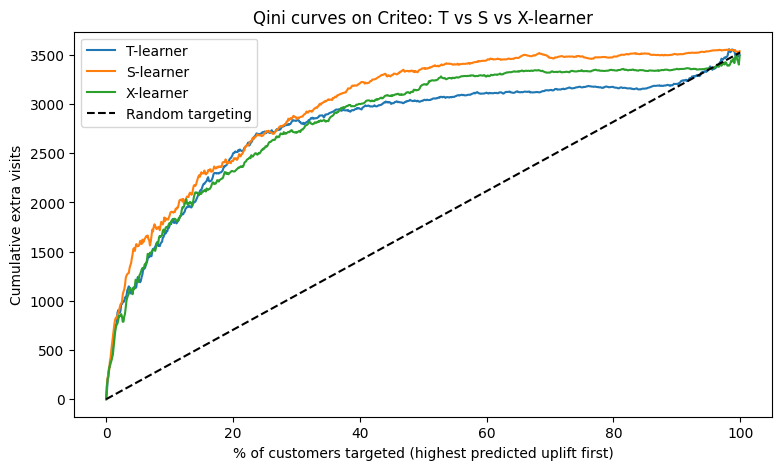

In [15]:
import matplotlib.pyplot as plt

def qini_points(y, uplift, t):
    """Qini curve: extra visits gained when targeting customers
    in order of predicted uplift (highest first)."""
    order = np.argsort(-uplift)
    y = np.asarray(y)[order]
    t = np.asarray(t)[order]

    n_treated = np.cumsum(t)              # treated people targeted so far
    n_control = np.cumsum(1 - t)          # control people targeted so far
    visits_treated = np.cumsum(y * t)     # visits among those treated
    visits_control = np.cumsum(y * (1 - t))

    # Extra visits = treated visits minus control visits, scaled to the same group size
    with np.errstate(divide='ignore', invalid='ignore'):
        qini = visits_treated - np.where(n_control > 0,
                                         visits_control * n_treated / n_control, 0)
    share_targeted = np.arange(1, len(y) + 1) / len(y)
    return share_targeted, qini

plt.figure(figsize=(9, 5))
for name, u in models.items():
    x, q = qini_points(y_test, u, t_test)
    step = 500   # plot every 500th point so the chart draws quickly
    plt.plot(x[::step] * 100, q[::step], label=name)

# Random targeting: a straight line from 0 to the total extra visits
plt.plot([0, 100], [0, q[-1]], 'k--', label='Random targeting')

plt.xlabel('% of customers targeted (highest predicted uplift first)')
plt.ylabel('Cumulative extra visits')
plt.title('Qini curves on Criteo: T vs S vs X-learner')
plt.legend()
plt.show()

### findings
- **Strong heterogeneity:** targeting the top 20% of users captures ~75% of all extra visits; beyond ~60%, extra users add almost nothing.
- **S-learner wins** (Qini AUC 0.081 vs 0.071 for X-learner and 0.067 for T-learner). The X-learner beat the T-learner as theory predicts, but the S-learner's shared model was more stable for this small effect.
- **Targeting the top 30% gives 2.65 pp lift vs 0.99 pp overall (~2.7x)**, compared with only ~1.1x on Hillstrom.
- **The models under-predict the average effect** (0.65 to 0.72 pp vs 0.99 pp actual). Ranking is still good, but profit calculations must use real test-set outcomes, not raw predicted values.
- **Caveat:** results are from one train/test split, so model differences of 10–20% may partly be noise.